Notebook to compute P3D following MW11 model. In this specific case we will use MW11 cosmology and vega's cddf (so that we can compare with cupix), but this is just an arbitrary example; any cosmology and cddf can be used. 

For comparisons between the model and ASTRID simulation measurements, check notebook "ModelvsASTRID"

In [1]:
import h5py
from lace.cosmo import cosmology
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
from w1_w2 import compute_w1_w2

In [2]:
# MW11 cosmology, for example
hubble, z = 0.71, 2.5
ombh2, omegam = 0.046*(hubble**2), 0.27
omch2 = omegam*(hubble**2)-ombh2
ns, As = 0.96, 2e-9
Fhcd = 0.9779  # Mean flux

cosmo = cosmology.Cosmology()
cosmo.CAMBparams.set_cosmology(H0=100*hubble, ombh2=ombh2, omch2=omch2)
cosmo.CAMBparams.InitPower.set_params(As=As, ns=ns)
print('WARNING: Changed to MW11 cosmology (It does not affect the f(NHI, X) function)')

In [3]:
wave_log = np.linspace(np.log10(2800), np.log10(6800), 2**12) # Angstrom
wave = 10**wave_log
bias_hcd, bias_lya = 2, -0.18

In [4]:
# Reading Vega f(n)
fn_file = '/pscratch/sd/l/lflores/astrid_hcd_outputs/fn_pyigm/fn_pyigm1'

with h5py.File(fn_file, 'r') as f:
    print('Atributes:')
    for m in f.attrs.keys():
        print(f'{m} = {f.attrs[m]}')
    logNHI_max = f.attrs['logNHI_max']
    logNHI_min = f.attrs['logNHI_min']
    print('----------------') 
    print('Data:')
    print(f.keys())

    NHirange = np.linspace(logNHI_min, logNHI_max) 
    logfNHiX = np.interp(NHirange, f['logNhi'][:], f['fn'][:][:, 0])
    fNHiX = 10**(logfNHiX)

Atributes:
Redshift = 2.5
logNHI_max = 21.3
logNHI_min = 17.2
----------------
Data:
<KeysViewHDF5 ['fn', 'logNhi']>


## W1 and W2

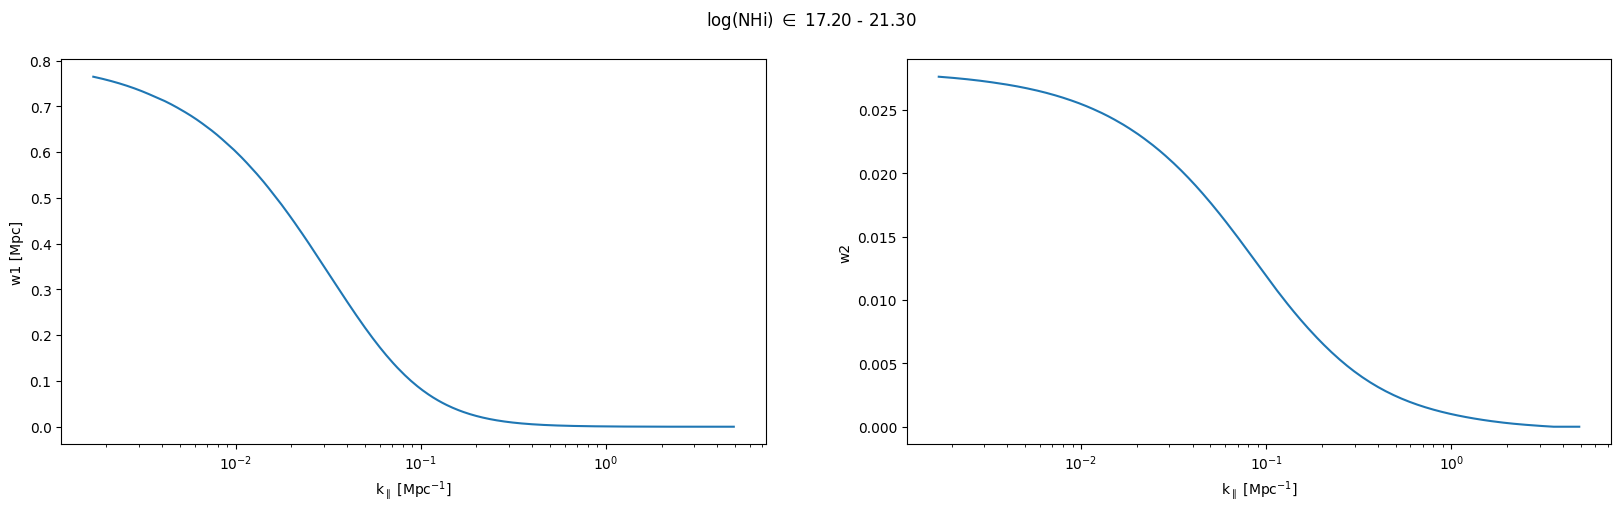

In [5]:
k_w1w2, w1, w2 = compute_w1_w2(wave, NHirange, fNHiX, z, hubble, omegam, resample=True)

plt.figure(figsize=(20, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()))

plt.subplot(1, 2, 1)
plt.plot(k_w1w2, w1)
plt.ylabel(r'w1 [Mpc]')
plt.xscale('log')
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]');

plt.subplot(1, 2, 2)
plt.plot(k_w1w2, w2)
plt.ylabel(r'w2')
plt.xscale('log')
plt.xlabel(r'k$_\parallel$ [Mpc$^{-1}$]');

In [6]:
# Warning, this depends a lot on the cosmology
bias_hcd_flux = -2*w2[1]/Fhcd
bias_hcd_flux

np.float64(-0.05651582502235199)

We will work in a grid of (k, mu), so for each value we will have a different k_los array. Let's create then the k_los grid and interpolate the w1 and w2 functions to it

In [7]:
mu = np.linspace(0, 1, 11)
k = np.logspace(-2.5, 0.5, len(k_w1w2))
k_los = k*mu[:, None]
k_perp = np.sqrt(k**2 - k_los**2)

w1_grid = np.interp(k_los, k_w1w2, w1)
w2_grid = np.interp(k_los, k_w1w2, w2)

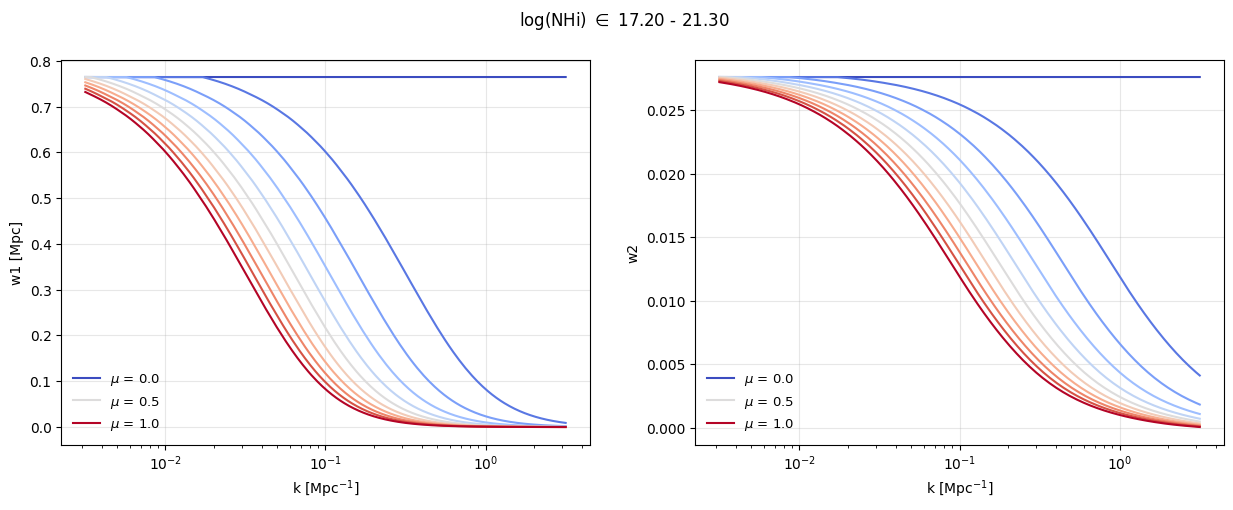

In [8]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()))

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, w1_grid[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, w1_grid[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'w1 [Mpc]');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, w2_grid[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, w2_grid[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'w2');

## Plin

In [9]:
plin = cosmo.get_linP_Mpc(z, k)

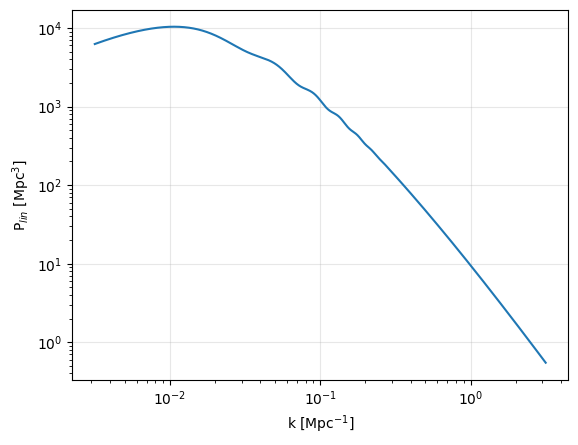

In [10]:
plt.plot(k, plin)
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{lin}$ [Mpc$^{3}$]');

## HCD field

In [11]:
p3d_hcd = (w2_grid**2)*((bias_hcd+mu[:, None]**2)**2)*plin

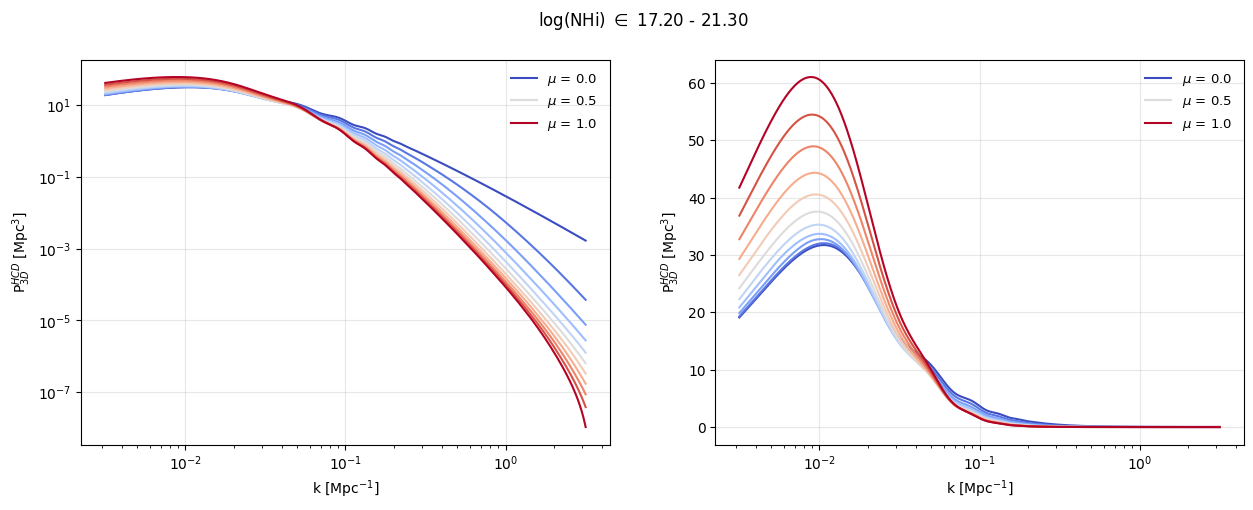

In [12]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()));

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_hcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_hcd[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{HCD}$ [Mpc$^{3}$]');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_hcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_hcd[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{HCD}$ [Mpc$^{3}$]');

## Lya field

In [13]:
dkms_dMpc = cosmo.get_dkms_dMpc(z)
k_d = 0.08*dkms_dMpc  # Mpc^-1
exp = np.exp(-(k_los**2/k_d**2))
p3d_lya = (bias_lya**2)*((1+mu[:, None]**2)**2)*exp*plin

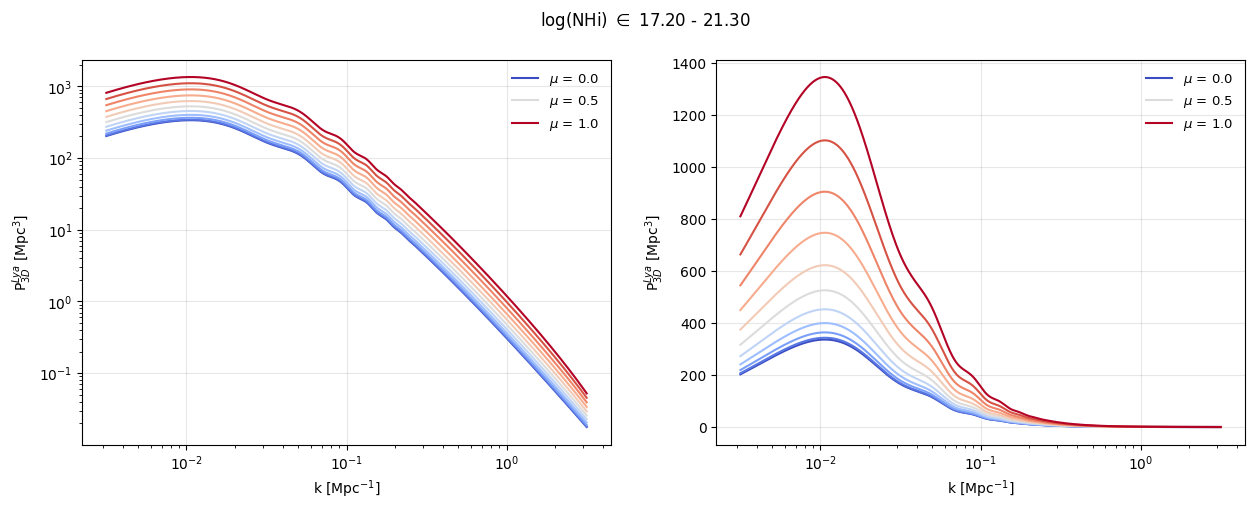

In [14]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()));

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lya[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lya[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$ [Mpc$^{3}$]');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lya[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lya[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$ [Mpc$^{3}$]');

## HCD x Lya field

In [15]:
dkms_dMpc = cosmo.get_dkms_dMpc(z)
k_d = 0.08*dkms_dMpc  # Mpc^-1
exp = np.exp(-(k_los**2/k_d**2))
p3d_lyahcd = w2_grid*(np.abs(bias_hcd) + mu[:, None]**2)*np.abs(bias_lya)*(1 + mu[:, None]**2)*plin*np.sqrt(exp)

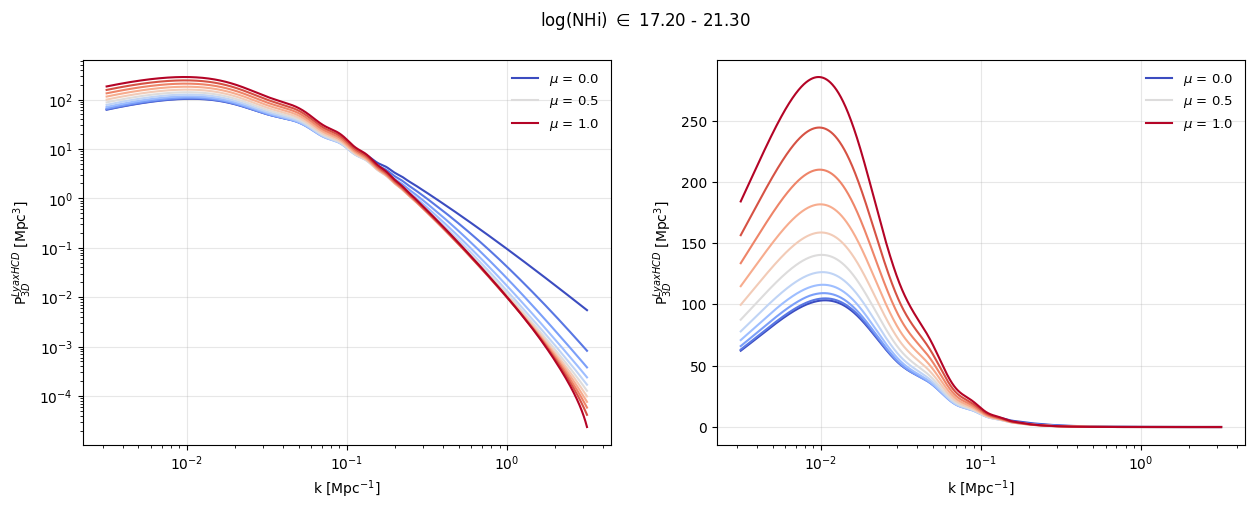

In [16]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()));

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lyahcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lyahcd[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{LyaxHCD}$ [Mpc$^{3}$]');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lyahcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lyahcd[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{LyaxHCD}$ [Mpc$^{3}$]');

## Total

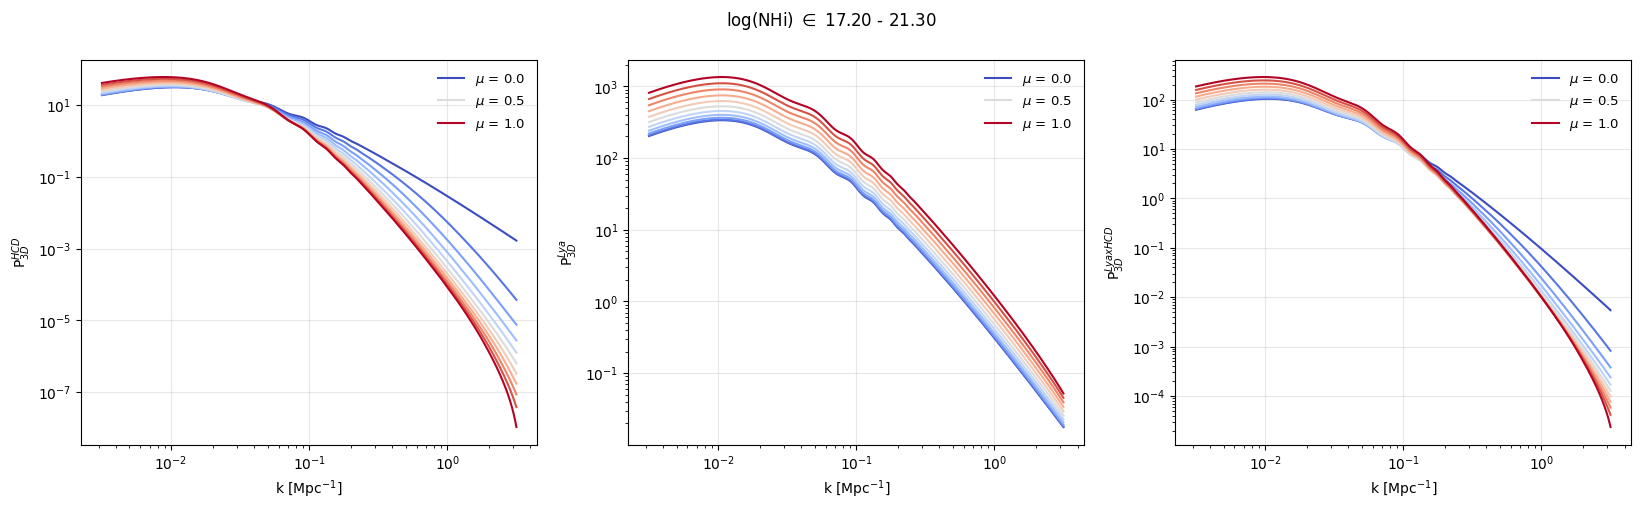

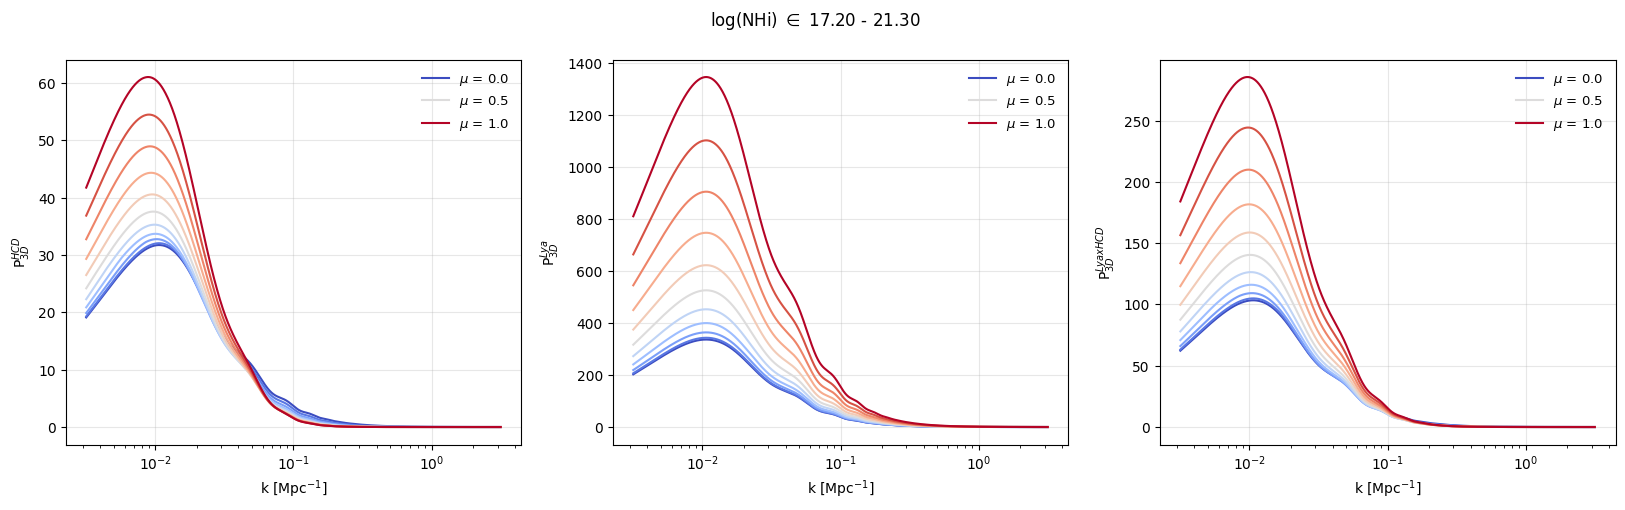

In [17]:
plt.figure(figsize=(20, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()))

plt.subplot(1, 3, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_hcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_hcd[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{HCD}$');

plt.subplot(1, 3, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lya[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lya[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$');

plt.subplot(1, 3, 3)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lyahcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lyahcd[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{LyaxHCD}$');

plt.figure(figsize=(20, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()))

plt.subplot(1, 3, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_hcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_hcd[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{HCD}$');

plt.subplot(1, 3, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lya[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lya[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$');

plt.subplot(1, 3, 3)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_lyahcd[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_lyahcd[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{LyaxHCD}$');

In [18]:
p3d_total = p3d_hcd + p3d_lya + 2*p3d_lyahcd

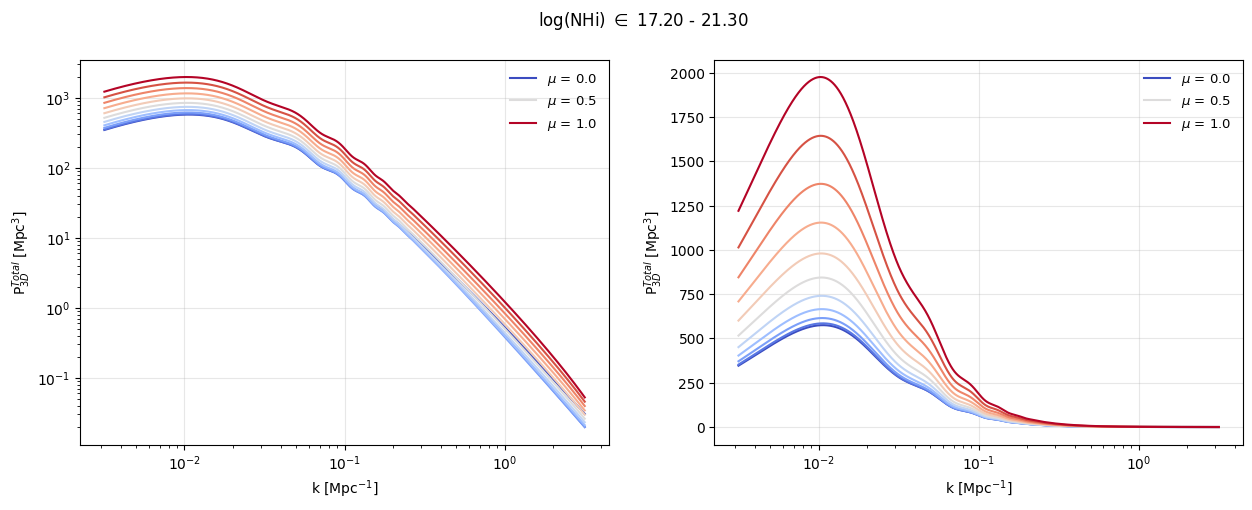

In [19]:
plt.figure(figsize=(15, 5))
plt.suptitle(r'log(NHi) $\in$ %.2f - %.2f' %(NHirange.min(), NHirange.max()));

plt.subplot(1, 2, 1)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_total[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_total[i, :])
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Total}$ [Mpc$^{3}$]');

plt.subplot(1, 2, 2)
colors = plt.cm.coolwarm(np.linspace(0,1,len(mu)))     
plt.gca().set_prop_cycle('color', colors)

for i in np.arange(len(mu)):
    if i in [0, 5, 10]:
        plt.plot(k, p3d_total[i, :], label = '$\mu$ = %.1f' %mu[i])
    else:
        plt.plot(k, p3d_total[i, :])
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Total}$ [Mpc$^{3}$]');

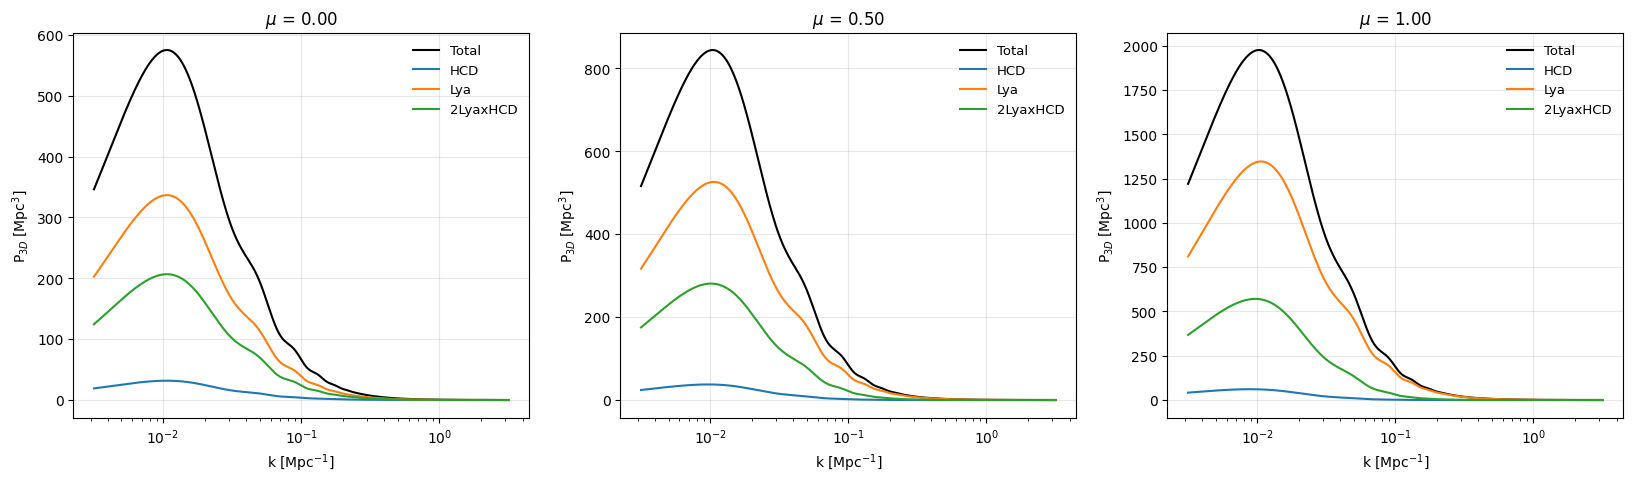

In [20]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
i = 0
plt.plot(k, p3d_total[i], color='k', label='Total')
plt.plot(k, p3d_hcd[i], label='HCD')
plt.plot(k, p3d_lya[i], label='Lya')
plt.plot(k, 2*p3d_lyahcd[i], label='2LyaxHCD')

plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^{3}$]')
plt.title(r'$\mu$ = %.2f' %mu[i])

plt.subplot(1, 3, 2)
i = 5
plt.plot(k, p3d_total[i], color='k', label='Total')
plt.plot(k, p3d_hcd[i], label='HCD')
plt.plot(k, p3d_lya[i], label='Lya')
plt.plot(k, 2*p3d_lyahcd[i], label='2LyaxHCD')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^{3}$]')
plt.title(r'$\mu$ = %.2f' %mu[i])

plt.subplot(1, 3, 3)
i = 10
plt.plot(k, p3d_total[i], color='k', label='Total')
plt.plot(k, p3d_hcd[i], label='HCD')
plt.plot(k, p3d_lya[i], label='Lya')
plt.plot(k, 2*p3d_lyahcd[i], label='2LyaxHCD')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^{3}$]')
plt.title(r'$\mu$ = %.2f' %mu[i]);

## Comparison with MW11

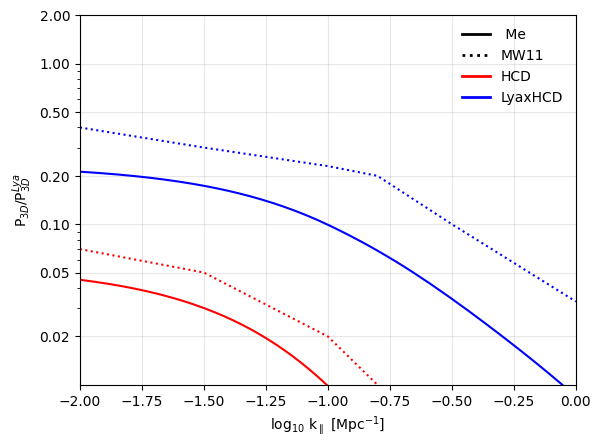

In [21]:
from matplotlib.lines import Line2D

k_mw11 = [-2, -1.5, -1, -0.8, -0.5, 0]
ratio_hcd_mw11 = [0.07, 0.05, 0.02, 0.01, np.nan, np.nan]
ratio_lyahcd_mw11 = [0.4, 0.3, 0.23, 0.2, 0.1, 0.033]

i = 10  # So that k = k_los
plt.plot(np.log10(k), p3d_hcd[i]/p3d_lya[i], color='red', label='HCD')
plt.plot(k_mw11, ratio_hcd_mw11, color='red', linestyle=':', label='MW11')
plt.plot(np.log10(k), p3d_lyahcd[i]/p3d_lya[i], color='blue', label='Me')
plt.plot(k_mw11, ratio_lyahcd_mw11, color='blue', linestyle=':', label='LyaxHCD')
plt.yscale('log')
yticks = np.array([0.02, 0.05, 0.10, 0.20, 0.50, 1.00, 2.00])
plt.yticks(yticks, [f"{y:.2f}" for y in yticks])
plt.grid(alpha=0.3)
handles = [Line2D([0], [0], color='black', lw=2, linestyle='-', label=' Me'),
    Line2D([0], [0], color='black', lw=2, linestyle=':', label='MW11'),
    Line2D([0], [0], color='red', lw=2, label='HCD'),
    Line2D([0], [0], color='blue', lw=2, label=r'LyaxHCD')]
plt.legend(handles=handles, frameon=False)
plt.xlabel(r'log$_{10}$ k$_\parallel$ [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$/P$_{3D}^{Lya}$')
plt.xlim(-2, 0)
plt.ylim(0.01, 2);